# Анализ и прогнозирование временных рядов методами искусственного интеллекта

## **Практическая работа 5. Поиск типичных подпоследовательностей временного ряда.**

In [1]:
%load_ext autoreload
%autoreload 2

Импорт библиотек и модулей

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from modules.snippets import *
from scipy import signal
from stumpy import snippets

d:\Venvs\.dm_venv\Lib\site-packages\stumpy\__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


### **Задача 1. Поиск сниппетов одномерного временного ряда**

В первой задаче необходимо выполнить поиск сниппетов одномерного временного ряда. Расмотрите приведенный ниже пример использования алгоритма SnipperFinder и визуализации полученных результатов для искуственного врменного ряда.

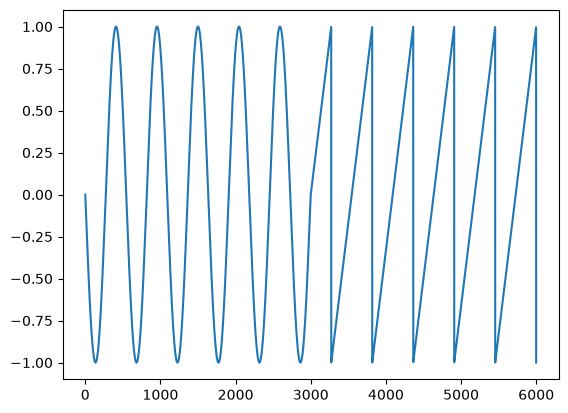

In [3]:
#Создание искусственного временного ряда
t = np.linspace(np.pi, 6 * 2 * np.pi, 3000)
ts = np.concatenate([np.sin(t), signal.sawtooth(t)])
plt.plot(ts)
plt.show()

In [4]:
#Поиск сниппетов
snp = snippets(ts, 600, 2, percentage=0.5)

600


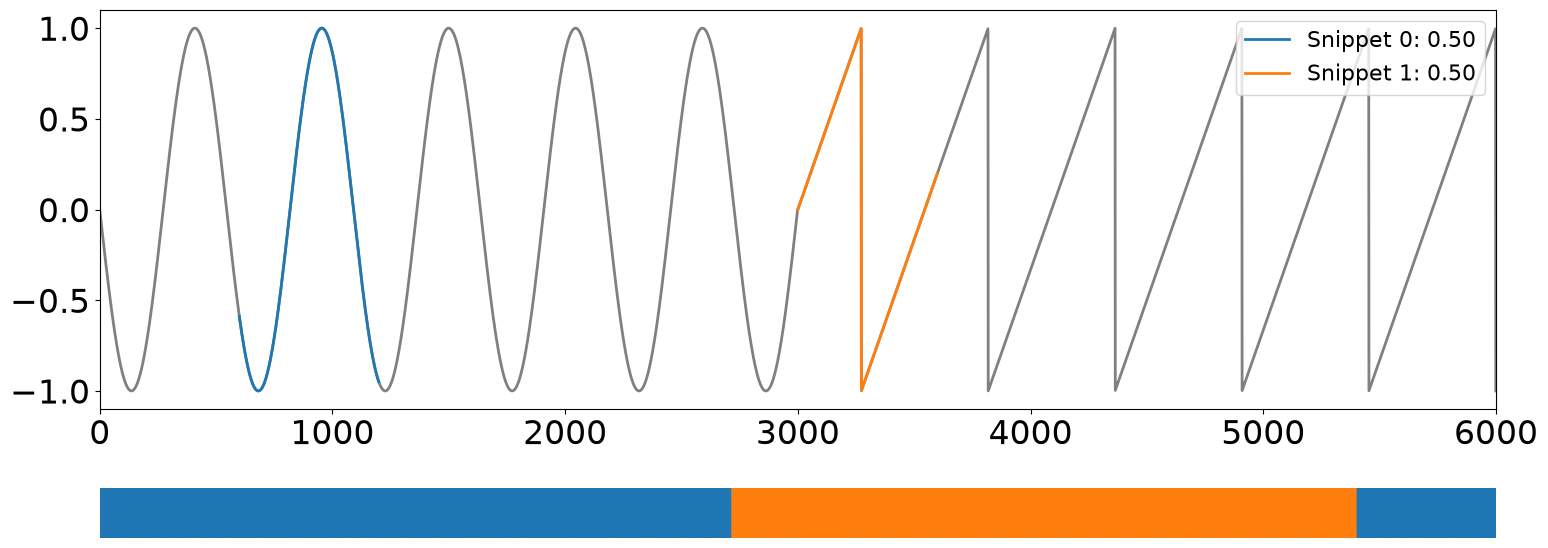

<Axes: >

In [5]:
#Визуализация результатов
plot_snippets(ts, snp)

Далее вам предстоит самостоятельно выполнить поиск top-$k$ типичных подпоследовательностей временного ряда (сниппетов) с помощью алгоритма SnippetFinder на наборе данных PAMAP. Описание набора данных находится в [README-файле](datasets/PAMAP/readme.md).

Выполните считывание временного ряда **показаний гироскопа на оси «Y» (угол тангажа) на временном интервале от 1790 сек. до 1930 сек.** (используя колонку с временными метками) из файла *PAMAP.txt*, который располагается в директории *./datasets/PAMAP*. Затем выполните поиск сниппетов с помощью функции `snippets()` из библиотеки stumpy. Затем визуализируйте полученные результаты, используя функцию `plot_snippets()` из модуля snippets.py.

In [6]:
with open(r"datasets\PAMAP\PAMAP.txt", mode='r') as f:
    data = f.readlines()
len(data), type(data)

(20, list)

In [7]:
t = np.array(list(map(float, data[0].split())))
ts = np.array(list(map(float, data[11].split())))
labels = np.array(list(map(int, map(float, data[1].split()))))
t.shape, ts.shape, labels.shape

((146000,), (146000,), (146000,))

In [8]:
indices = np.where((t > 1790) & (t < 1930))
ts = ts[indices]
labels = labels[indices]
ts.shape

(13429,)

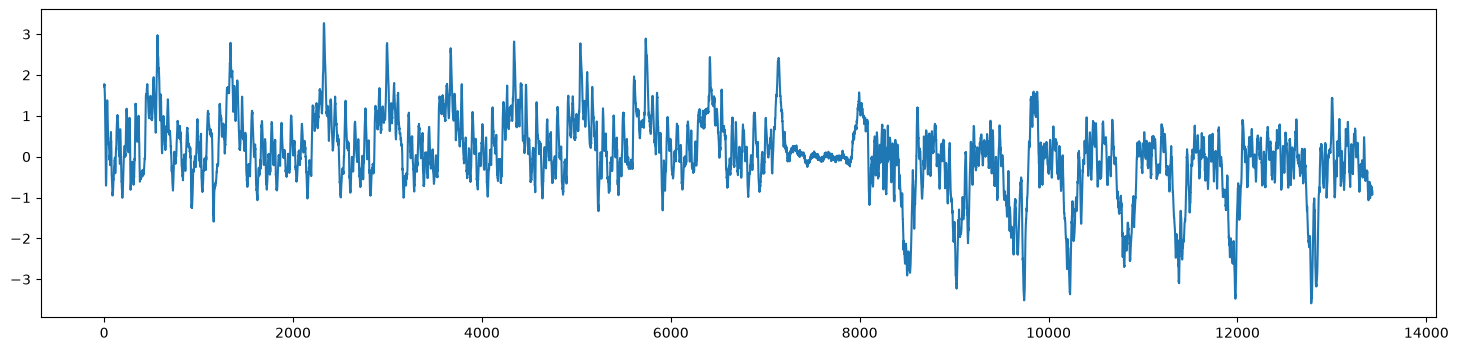

In [9]:
plt.figure(figsize=(18, 4))
plt.plot(ts)
plt.show()

In [10]:
np.unique(labels)

array([12, 13])

12 - подъём по лестнице.<br>
13 - спуск с лестницы.

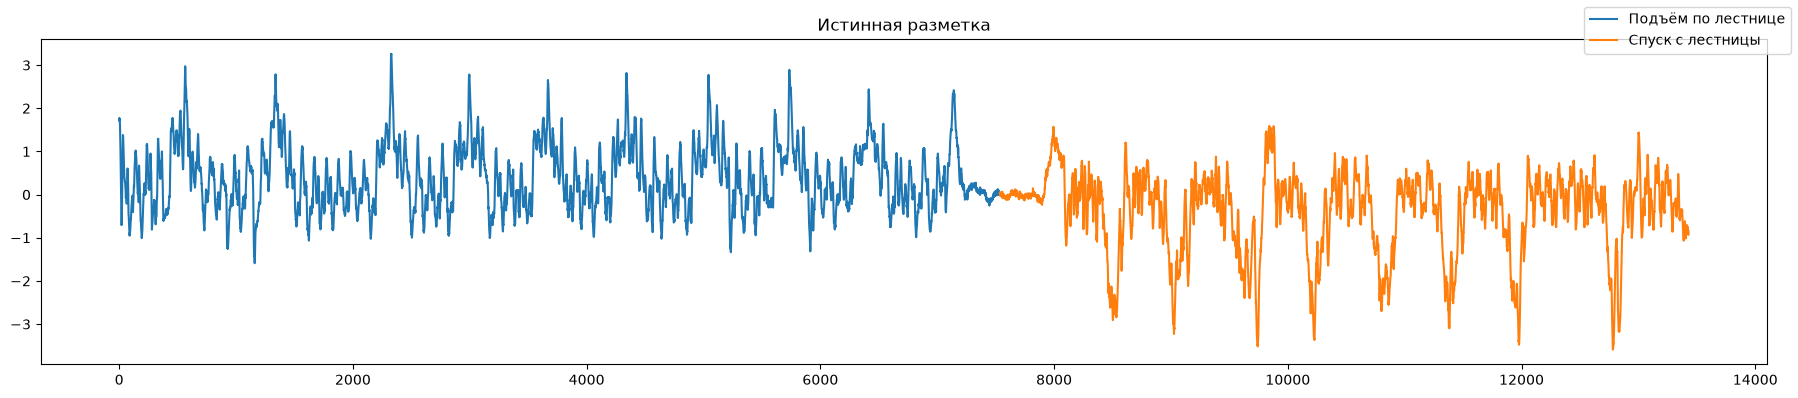

In [11]:
fig = plt.figure(figsize=(18, 4))
ax = fig.add_subplot(1, 1, 1)
ax.set_title("Истинная разметка")

label2name = {
    12: "Подъём по лестнице",
    13: "Cпуск с лестницы"
}

for label, name in label2name.items():
    tmp_ts = np.where(labels == label, ts, np.nan)
    ax.plot(tmp_ts, label=name)

fig.legend()
fig.tight_layout()
plt.show()

Выполните визулизацию временного ряда и найденных сниппетов с помощью функции `plot_snippets()` из модуля snippets.py.

In [12]:
k = 2
m = 600
snp = snippets(ts, m, k, percentage=0.5)

In [13]:
snp

(array([[ 0.246836,  0.219834,  0.291604, ..., -0.70485 , -0.755376,
         -0.733111],
        [-2.69873 , -2.70049 , -2.66432 , ..., -1.4147  , -1.37338 ,
         -1.32408 ]], shape=(2, 600)),
 array([ 6000, 10800]),
 array([[ 7.36529123,  7.17583661,  7.11598251, ..., 16.51904422,
         16.59805665, 16.71479234],
        [12.32513579, 12.32513579, 12.32513579, ..., 11.43114069,
         11.38081989, 11.37310339]], shape=(2, 12830)),
 array([0.57848792, 0.42151208]),
 array([135052.32578999, 108535.50381276]),
 array([[    0,     0,   363],
        [    0,   529,  2838],
        [    0,  2912,  3521],
        [    0,  3559,  5619],
        [    0,  5624,  6280],
        [    0,  6299,  7000],
        [    0,  7372,  7864],
        [    0,  8747,  8965],
        [    0, 12761, 12775],
        [    1,   363,   529],
        [    1,  2838,  2912],
        [    1,  3521,  3559],
        [    1,  5619,  5624],
        [    1,  6280,  6299],
        [    1,  7000,  7372],
        [  

600


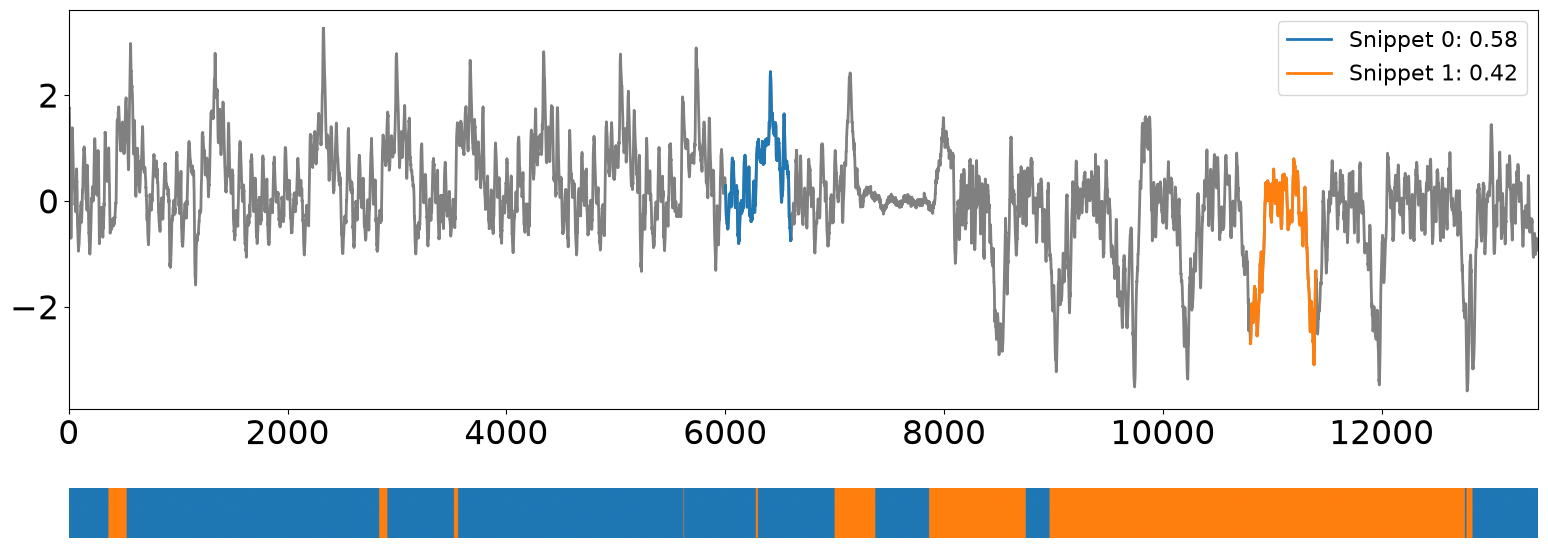

<Axes: >

In [14]:
plot_snippets(ts, snp)

Оцените точность разметки, полученной при помощи сниппетов, используя исходные данные об активностях в ряде.

In [15]:
pred = np.zeros_like(ts)
snippets_regimes = snp[5]
for r in snippets_regimes:
    pred[r[1]: r[2]] = r[0]
pred

array([0., 0., 0., ..., 0., 0., 0.], shape=(13429,))

In [16]:
# 0 - 12, 1 - 13
pred = np.where(pred == 0, 12, 13)
print(f"Accuracy: {(pred == labels).sum() / pred.shape[0]:.3f}")

Accuracy: 0.864


❓ Проанализируйте и изложите содержательный смысл полученных результатов.

Разметка временного ряда, сделанная с помощью поиска сниппетов, совпала с истинной примерно на 86%.

На графике с исходным временным рядом и найденными сниппетами отчетливо видно его разбиение на две части, что соответвует двум видам активности - подъём по лестнице и спуск с неё. Однако переход от одной активности к другой не удалось верно разметить.

### Задача 2. Разметка многомерного временного ряда

Выполните разметку многомерного временно ряда, используя **показания гироскопа по всем трем осям** из набора данных PAMAP. Используйте тот же временной интервал, что и в задаче 1. Итоговую разметку получите в результате голосования большинством.

In [17]:
tsx = np.array(list(map(float, data[10].split())))[indices]
tsy = ts
tsz = np.array(list(map(float, data[12].split())))[indices]
ts = np.array([tsx, tsy, tsz])

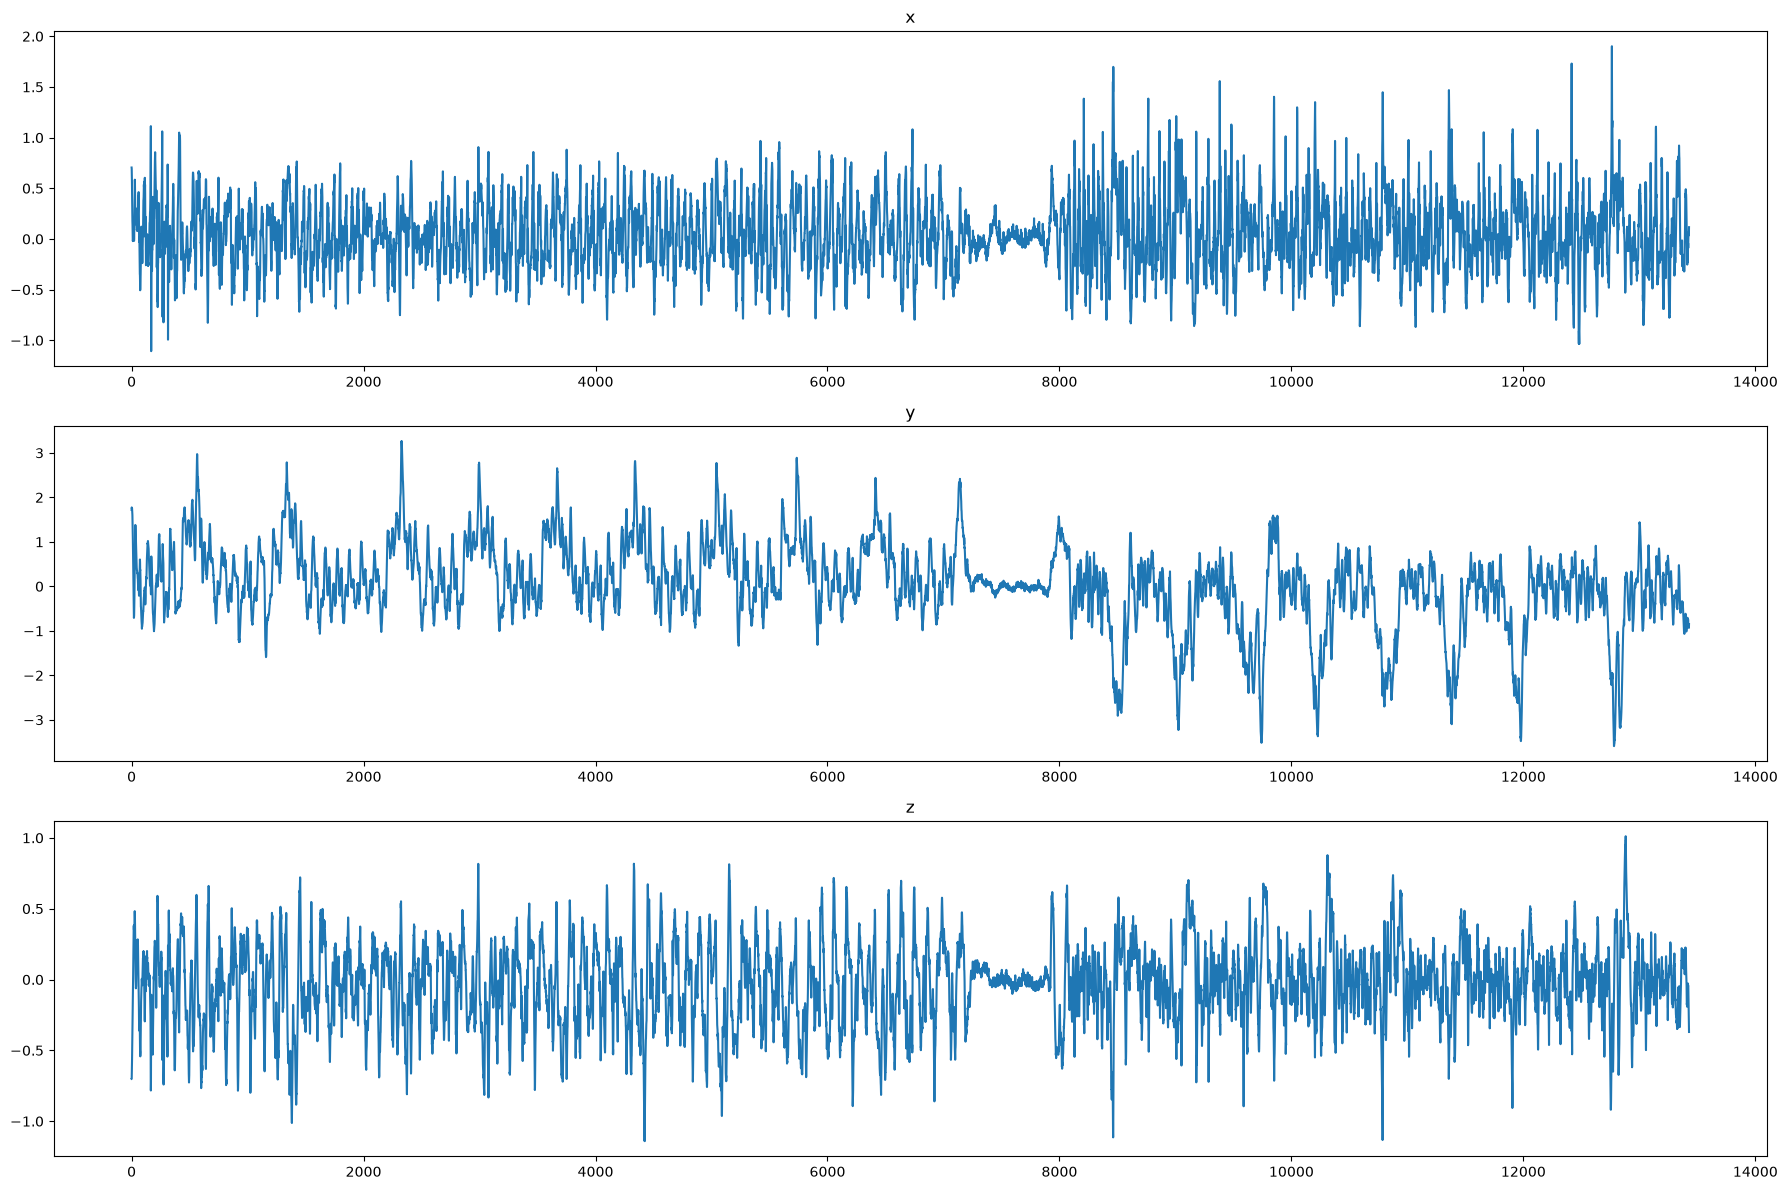

In [18]:
rows = 3
fig = plt.figure(figsize=(18, rows * 4))
ax_names = ('x', 'y', 'z')

for i in range(rows):
    ax = fig.add_subplot(rows, 1, i + 1)
    ax.plot(ts[i])
    ax.set_title(ax_names[i])

fig.tight_layout()
plt.show()

600


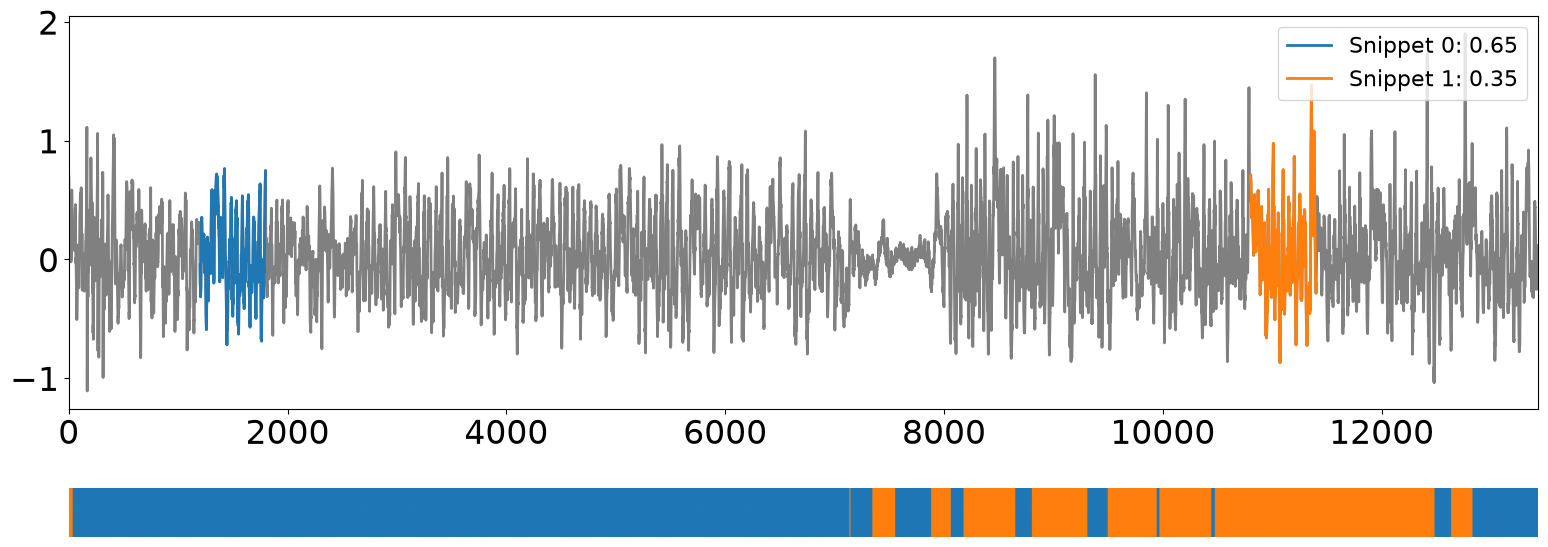

600


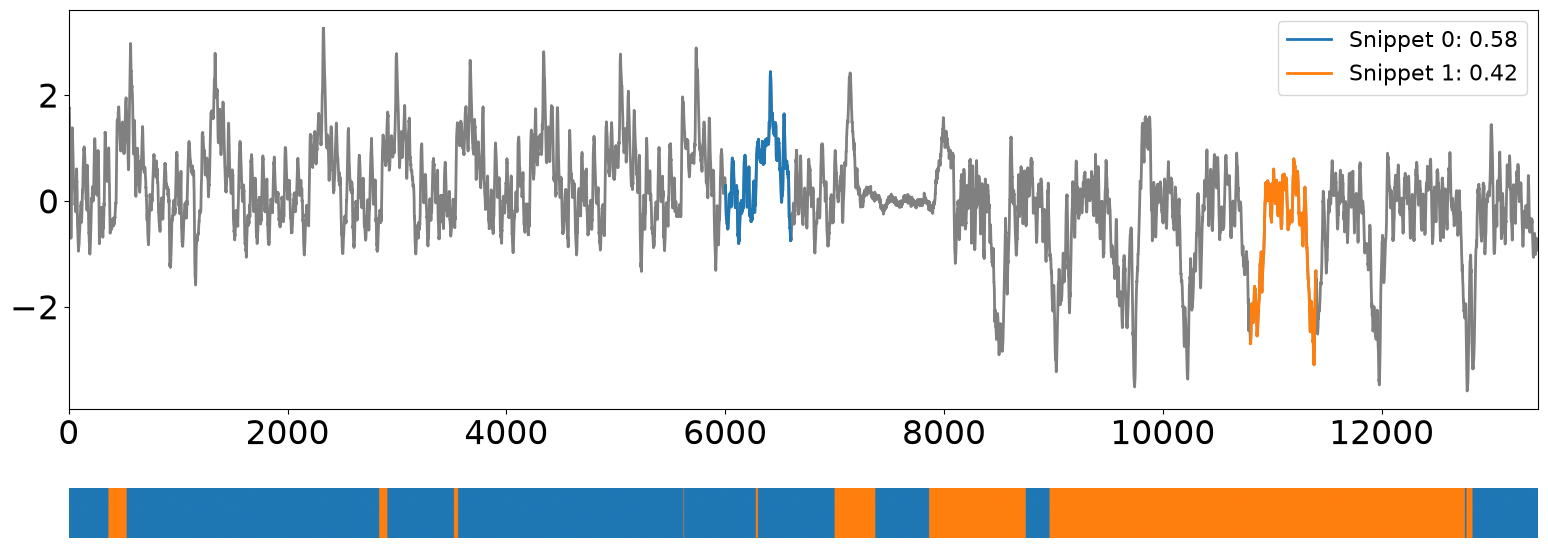

600


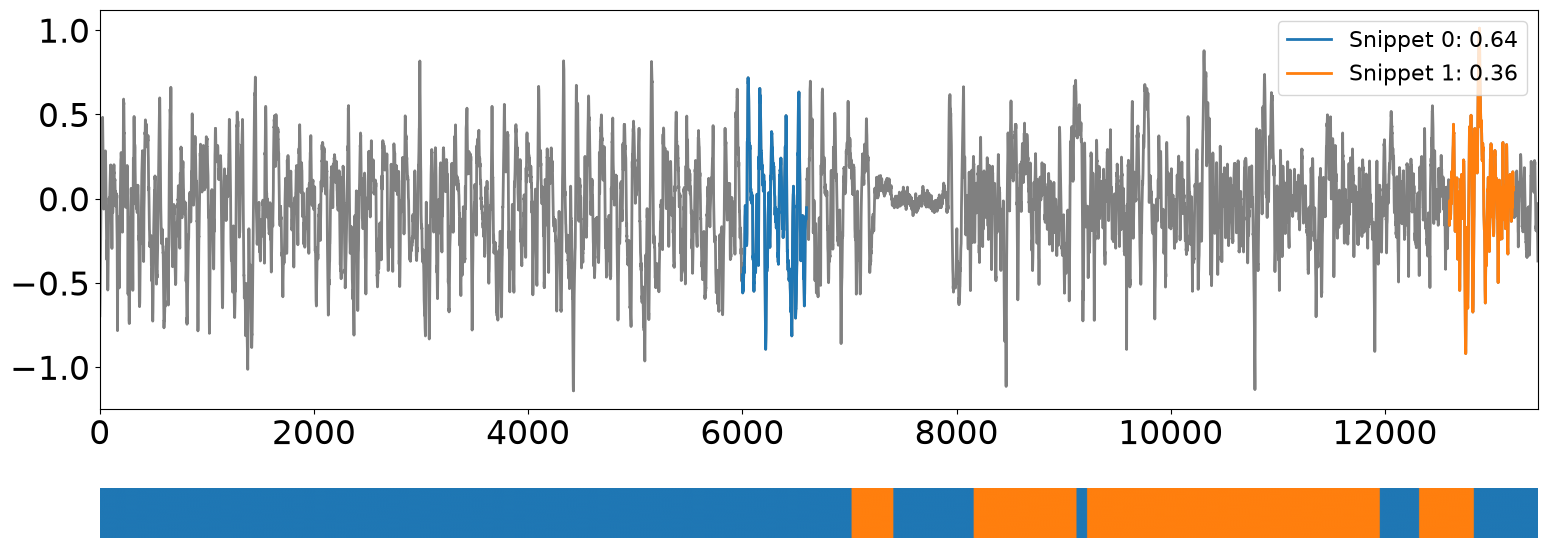

array([[1., 1., 1., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(3, 13429))

In [19]:
k = 2
m = 600

preds = np.zeros_like(ts)
for i in range(ts.shape[0]):
    snp = snippets(ts[i], m, k, percentage=0.5)
    plot_snippets(ts[i], snp)
    snippets_regimes = snp[5]
    for r in snippets_regimes:
        preds[i][r[1]: r[2]] = r[0]
preds

In [20]:
from scipy.stats import mode

In [21]:
pred = mode(preds, axis=0)[0]

Оцените точность разметки многомерного ряда, используя исходные данные об активностях.

In [22]:
# 0 - 12, 1 - 13
pred = np.where(pred == 0, 12, 13)
print(f"Accuracy: {(pred == labels).sum() / pred.shape[0]:.3f}")

Accuracy: 0.889


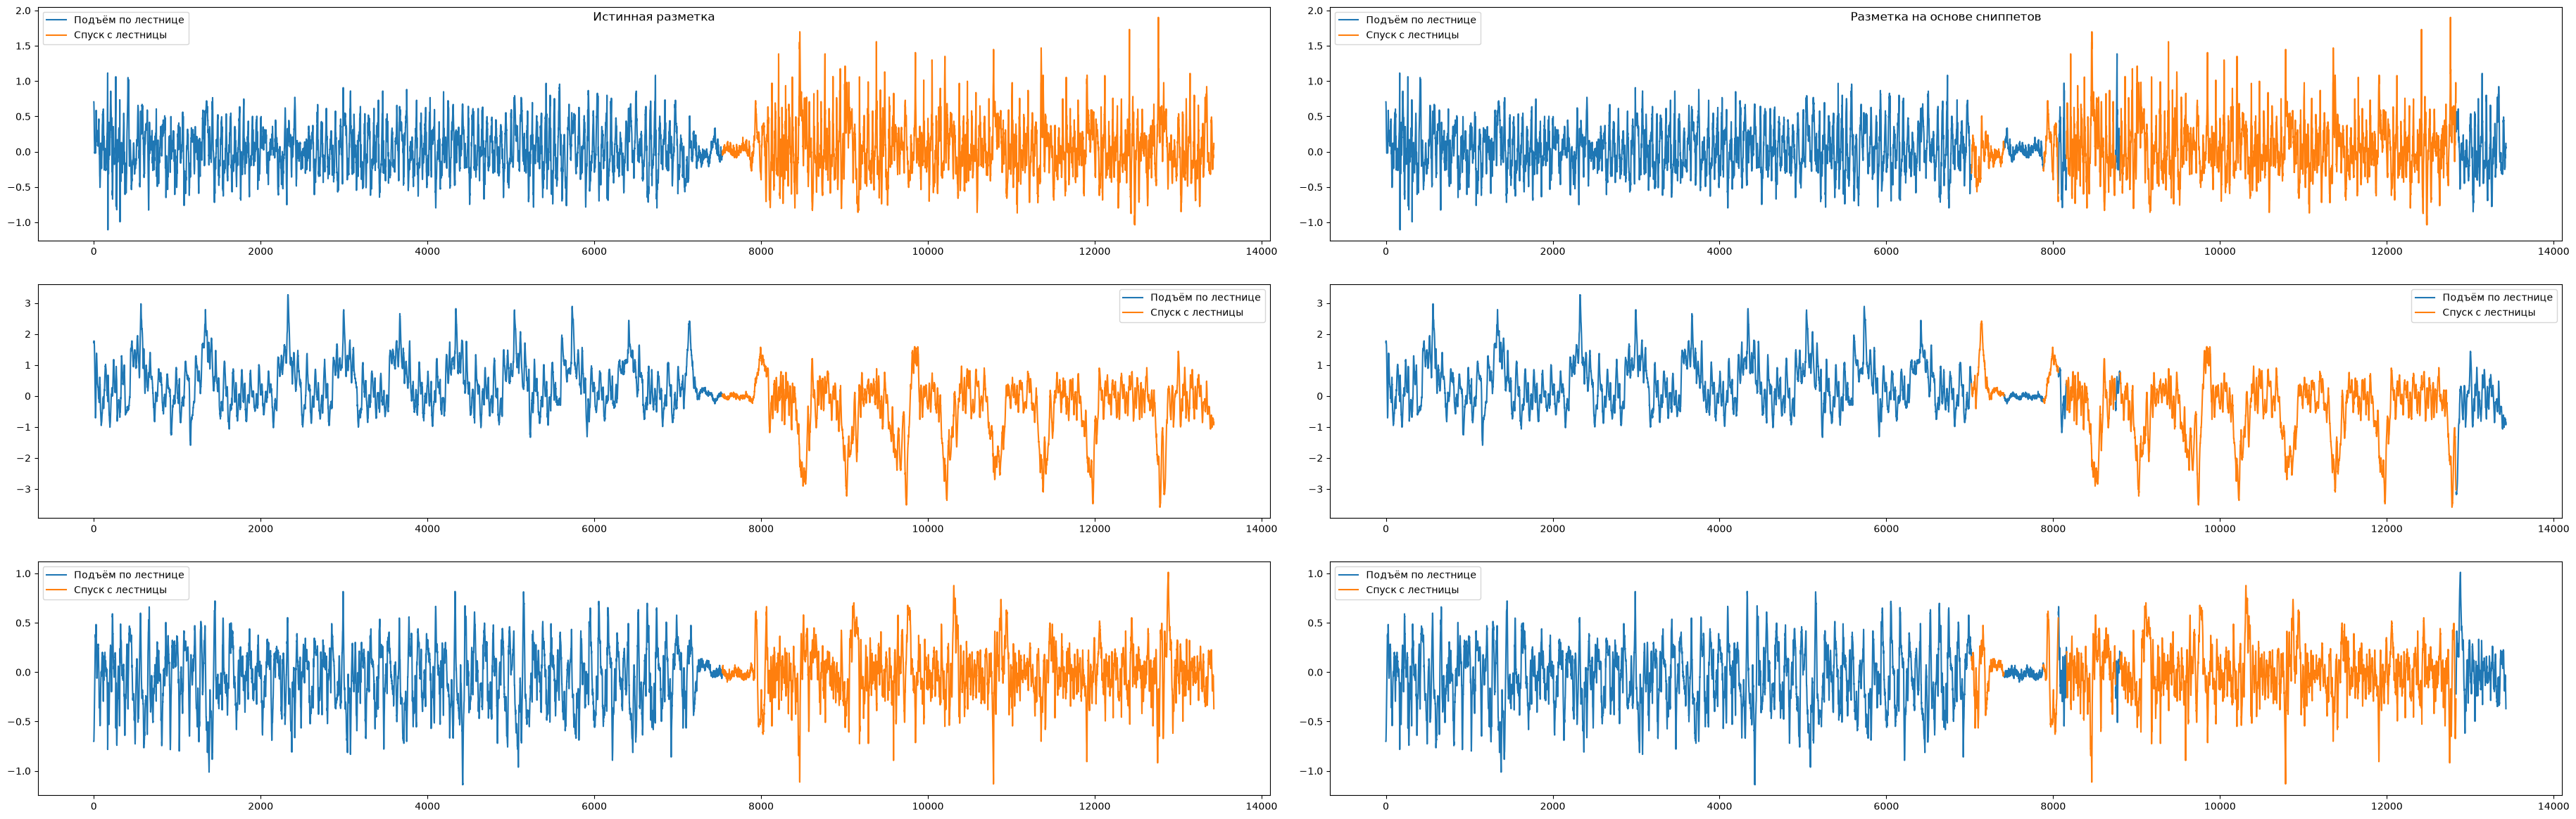

In [23]:
rows = ts.shape[0]
fig = plt.figure(figsize=(36, rows * 4))
subfigs = fig.subfigures(1, 2, wspace=0.04)

subfigs[0].suptitle("Истинная разметка")
for i in range(rows):
    ax = subfigs[0].add_subplot(rows, 1, i + 1)
    for label, name in label2name.items():
        tmp_ts = np.where(labels == label, ts[i], np.nan)
        ax.plot(tmp_ts, label=name)
        ax.legend()

subfigs[1].suptitle("Разметка на основе сниппетов")
for i in range(rows):
    ax = subfigs[1].add_subplot(rows, 1, i + 1)
    for label, name in label2name.items():
        tmp_ts = np.where(pred == label, ts[i], np.nan)
        ax.plot(tmp_ts, label=name)
        ax.legend()

fig.tight_layout()
plt.show()

❓ Проанализируйте и изложите содержательный смысл полученных результатов. Сравните полученные разметки многомерного и одномерного рядов.

Точность разметки многомерного временного ряда на основе сниппетов равна примерно 89%, что на 3% больше, чем разметка одномерного временного ряда. Увеличение точности можно объяснить тем, что определение класса объекта голосованием, обычно точнее, чем без него.

В разметке одномерного временного ряда есть неточности в его левой части, а в разметке многомерного временного ряда левая часть размечена верно. И для многомерного, и для одномерного временного ряда не удалось верно разметить переход от одной активности к другой.

## Задача 3. Подбор оптимального значения _k_


Разработайте программу, которая выполняет выполняет вычисление меры $change$ для различных значений $k$ с помощью алгоритма SnippetFinder. Проведите эксперименты, используя временной ряд из задания 2 (взяв 1 ≤ _k_ ≤ 9).

$Change_k = \frac{ProfileArea_{k-1}}{ProfileArea_k} - 1$

In [24]:
k_values = list(range(1, 10))
m = 600

profile_areas = []

for k in k_values:
    profile_area = 0
    for i in range(ts.shape[0]):
        snp = snippets(ts[i], m, k, percentage=0.5)
        profile_area += snp[2].min(axis=0).sum()
    profile_area /= ts.shape[0]
    profile_areas.append(profile_area)

change = []
for i in range(1, len(profile_areas)):
    change.append(profile_areas[i - 1] / profile_areas[i] - 1)

profile_areas, change

([np.float64(161054.93642604002),
  np.float64(139215.29856736027),
  np.float64(126298.33463576612),
  np.float64(117635.58767248406),
  np.float64(109419.12425539033),
  np.float64(101704.74098598423),
  np.float64(94165.93254079348),
  np.float64(87260.32746643558),
  np.float64(80540.52696950301)],
 [np.float64(0.15687670883464366),
  np.float64(0.10227343035714287),
  np.float64(0.07364052949181077),
  np.float64(0.07509165763304826),
  np.float64(0.07585077347052294),
  np.float64(0.08005876692109304),
  np.float64(0.07913796882110158),
  np.float64(0.08343377861777657)])

Выполните визуализацию результатов экспериментов в следующем виде: отображение столбчатых диаграм со значениями $ProfileArea$ и меры $change$ в зависимости от $k$.

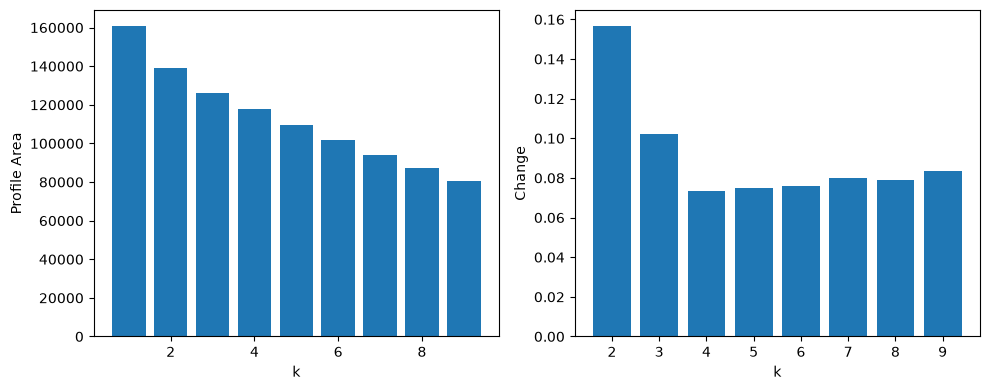

In [25]:
cols = 2
fig = plt.figure(figsize=(cols * 5, 4))

ax = fig.add_subplot(1, cols, 1)
ax.bar(k_values, profile_areas)
ax.set_xlabel("k")
ax.set_ylabel("Profile Area")

ax = fig.add_subplot(1, cols, 2)
ax.bar(k_values[1:], change)
ax.set_xlabel("k")
ax.set_ylabel("Change")

fig.tight_layout()
plt.show()

❓ Проанализируйте и изложите содержательный смысл полученных результатов. Какое значение $k$ является наилучшим для используемого временного ряда?

При увеличении k значение ProfileArea уменьшается.<br>
Мера Change показывает, насколько сильно изменится ProfileArea, если добавить еще один сниппет.<br>
На графике зависимости Change от k видно, что при k = 2 Change принимает наибольшее значение, следовательно, оптимальное число сниппетов для данного временного ряда равно 2. Это значит, что в нём есть 2 отчётливые подпоследовательности.<br>
Действительно, во временном ряду есть две активности - подъём по лестнице и спуск с неё.